**Eye-Tracking & Neurocognitive Intelligence | Reading Comprehension & Neurocognitive Modelling | Presented by: Reza Saadatyar (2026)**

**05 | Generalisation, Robustness and Final Evaluation**

![Generalisation, Robustness and Final Evaluation — scientific workflow](../../images/05_generalisation_and_final_evaluation.svg)

**Objective:** Reconcile held-out prediction scores, select on Validation, and report matched Test performance and conditional participant uncertainty.

**Dataset:** Fixed trial features, participant assignments and saved scores from Notebooks 03 and 04.

**Scope:** Compare fixed candidates on matched held-out trials, quantify conditional participant uncertainty and examine score calibration without further fitting.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("reading_comprehension_modelling")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# --------------------------- 3. Study Dependencies ---------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r",
     str(root / "reading_comprehension_modelling" / "requirements.txt")],
    check=True,
)

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------------ 5. Machine Learning Metrics ------------------------
from sklearn.metrics import confusion_matrix

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from onestop_io import validate_splits, validate_trial_index
from reading_evaluation import evaluate, participant_bootstrap

# ------------------- 8. Output Directory and Setup Summary -------------------
out_dir = root / "reading_comprehension_modelling" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=10, legend_size=10,
    figure_dpi=100, figure_size=(10, 5),
)
print("Study outputs:", out_dir)
print("Python:", sys.version.split()[0])


Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/reading_comprehension_modelling/output
Python: 3.13.16


**02. Reconcile Matched Held-Out Predictions**

Match the 160,018 saved classical and neural scores to the eligible trial identities, outcome labels and participant roles. Each of the 19 candidates per protocol must cover every assigned Validation and Test trial exactly once. The primary candidate for each protocol is selected by Validation Macro F1, with alphabetical model-name tie-breaking.

TF-IDF fusion is selected in Protocol A (Validation Macro F1 0.5582), and TF-IDF text in Protocol B (0.5698). All other Test comparisons are secondary and do not alter this selection.

In [3]:
# ================ 02. Reconcile Matched Held-Out Predictions =================

# ------------------- 1. Load and Reconcile Trial Features --------------------
identity = ["trial_id","participant_id","trial_index","article_batch",
            "article_key","paragraph_key","question_key","difficulty_level"]
table = pd.read_csv(out_dir/"02_trial_features.csv",dtype={c:str for c in identity})
index = pd.read_csv(out_dir/"01_trial_index.csv",dtype=str)
index["is_correct"] = index.is_correct.astype(int)
validate_trial_index(index,table)

# ------------------------- 2. Load Participant Roles -------------------------
splits = pd.read_csv(out_dir/"01_participant_splits.csv",dtype=str)
validate_splits(table,splits)

# --------------- 3. Reconcile Scores and Select on Validation ----------------
scores = pd.concat([pd.read_csv(out_dir/"03_classical_predictions.csv"),
                    pd.read_csv(out_dir/"04_neural_predictions.csv")],ignore_index=True)
data, validation, selected, test, people, strata, calibration = evaluate(table,splits,scores)
display(selected[["protocol","model","macro_f1","n_people","n_trials"]])


,protocol,model,macro_f1,n_people,n_trials
0,B_unseen_batch,tfidf_text,0.570210,24,1295
1,A_unseen_people,tfidf_fusion,0.557059,36,1943


**03. Compare Test Performance and Generalisation**

Use Macro F1 as the primary metric, complemented by accuracy, balanced accuracy, AUROC, incorrect-response precision, recall and area under the precision–recall curve (AUPRC).

| Metric | A: TF-IDF fusion | B: TF-IDF text |
| --- | ---: | ---: |
| Test participants / trials | 36 / 1,944 | 60 / 3,240 |
| Macro F1 | 0.5560 | 0.5035 |
| Accuracy | 0.6224 | 0.6389 |
| Balanced accuracy | 0.6161 | 0.5116 |
| AUROC | 0.6573 | 0.5386 |
| Incorrect AUPRC | 0.3002 | 0.2050 |
| Incorrect precision | 0.2813 | 0.2032 |
| Incorrect recall | 0.6058 | 0.3058 |

The prevalence reference achieves Macro F1 of 0.4462 and 0.4473 with zero incorrect-response recall. The selected A candidate approximately retains its Validation performance, whereas the selected B candidate shows limited discrimination. Protocol B changes participants and articles together; the difference between protocols is not an isolated unseen-text effect.

TF-IDF fusion attains the highest secondary Test Macro F1 in B (0.5296), but TF-IDF text remains the primary candidate selected on Validation.

,protocol,model,n_people,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
12,A_unseen_people,tfidf_fusion,36,1944,0.621399,0.555192,0.615490,0.657183,0.300654,0.280637,0.605820,0.227256
13,A_unseen_people,tfidf_text,36,1944,0.618313,0.551566,0.610564,0.654215,0.293365,0.276961,0.597884,0.225549
4,A_unseen_people,forest_text,36,1944,0.619342,0.548071,0.601168,0.640333,0.278454,0.272040,0.571429,0.219270
18,A_unseen_people,xgb_text,36,1944,0.565329,0.518373,0.597747,0.627657,0.294445,0.256517,0.650794,0.235385
10,A_unseen_people,mlp_text,36,1944,0.609053,0.518247,0.548623,0.570147,0.259325,0.235457,0.449735,0.242702
16,A_unseen_people,xgb_fusion,36,1944,0.587449,0.513480,0.557289,0.586242,0.270807,0.237624,0.507937,0.238020
0,A_unseen_people,cnn_fusion,36,1944,0.573560,0.501525,0.544654,0.578966,0.264047,0.227328,0.497354,0.244042
5,A_unseen_people,gru_fusion,36,1944,0.574074,0.498182,0.536946,0.572520,0.256523,0.222222,0.476190,0.243709
14,A_unseen_people,transformer_fusion,36,1944,0.567901,0.497420,0.541142,0.574632,0.277909,0.224344,0.497354,0.244390
15,A_unseen_people,transformer_gaze,36,1944,0.680556,0.491676,0.491653,0.520324,0.211044,0.181102,0.182540,0.245468


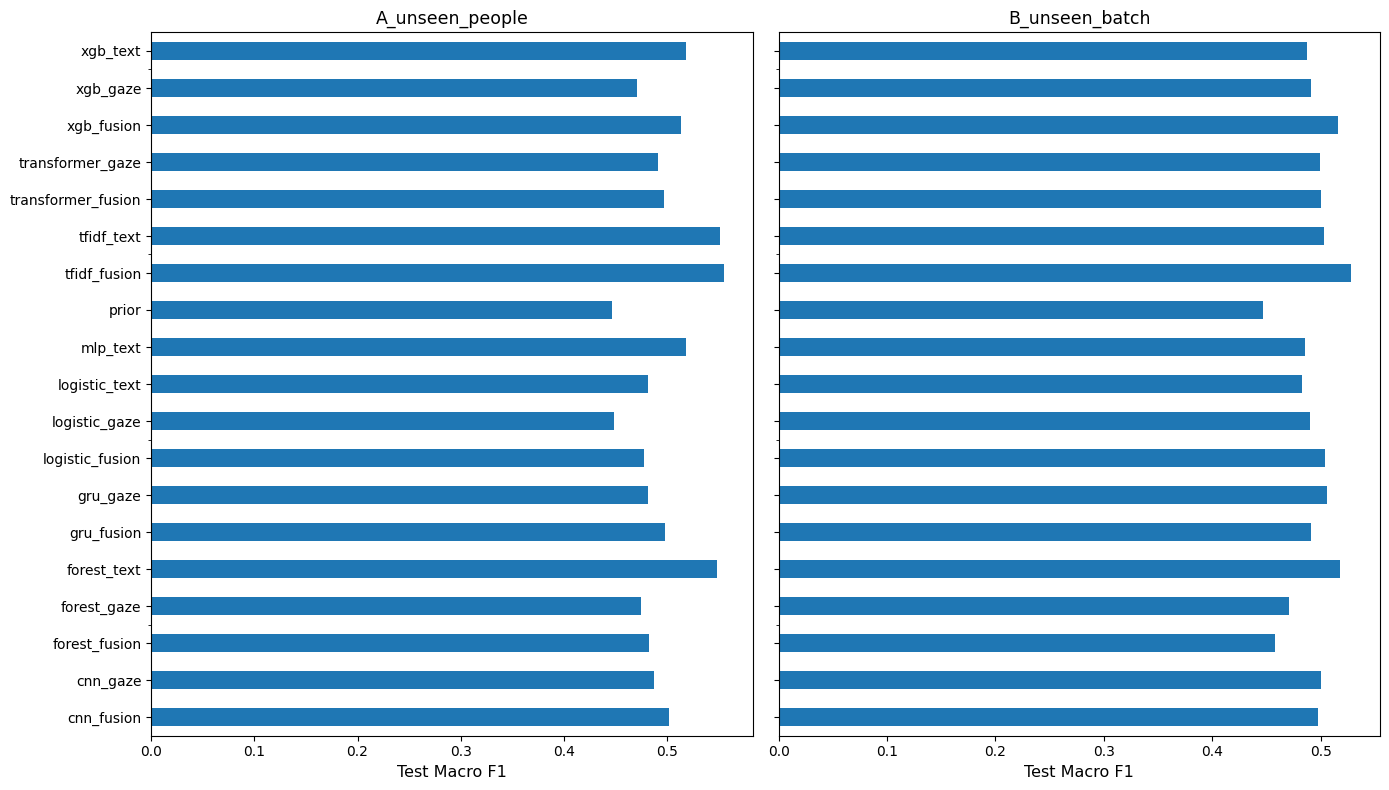

In [4]:
# ============== 03. Compare Test Performance and Generalisation ==============

# ----------------------- 1. Summarise Held-Out Metrics -----------------------
display(test.sort_values(["protocol","macro_f1"],ascending=[True,False]))

# ------------------------ 2. Plot Held-Out Comparison ------------------------
fig, axes = plt.subplots(1,2,figsize=(14,8),sharey=True)
for ax,(protocol,g) in zip(axes,test.groupby("protocol")):
    g.sort_values("model").plot.barh(x="model",y="macro_f1",ax=ax,legend=False)
    ax.set(title=protocol,xlabel="Test Macro F1",ylabel="")
fig.tight_layout()
save_figure(fig,out_dir/"05_test_comparison.png")
plt.show()


**04. Analyse Participant Variation and Difficulty**

Summarise Test performance by participant and difficulty. For single-class participant subsets, AUROC, balanced accuracy and incorrect AUPRC are undefined under the implemented metric convention and remain missing rather than being replaced with zero.

Selected-model participant Macro F1 ranges from 0.3448 to 0.6842 (median 0.5261) in A and 0.3721 to 0.7146 (median 0.4893) in B. Advanced/elementary pooled Macro F1 is 0.5606/0.5489 in A and 0.4904/0.4996 in B. Difficulty strata are observational, not causal estimates.

The confusion matrices use observed classes as rows and predicted classes as columns (0 = incorrect, 1 = correct). The selected models identify 229 of 378 incorrect responses in A and 189 of 618 in B.

,protocol,model,participant_id,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
0,A_unseen_people,cnn_fusion,l10_341,54,0.592593,0.541667,0.589286,0.563492,0.331659,0.291667,0.583333,0.245567
1,A_unseen_people,cnn_fusion,l12_207,54,0.537037,0.498328,0.508224,0.536184,0.303237,0.304348,0.437500,0.250366
2,A_unseen_people,cnn_fusion,l12_92,54,0.592593,0.469643,0.502717,0.480978,0.194954,0.150000,0.375000,0.245742
3,A_unseen_people,cnn_fusion,l17_98,54,0.574074,0.401446,0.460784,0.575163,0.082207,0.045455,0.333333,0.243218
4,A_unseen_people,cnn_fusion,l20_253,54,0.722222,0.719820,0.722222,0.694102,0.773397,0.772727,0.629630,0.235158


,protocol,model,difficulty,n_people,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
0,A_unseen_people,cnn_fusion,Adv,36,972,0.467078,0.446822,0.546553,0.606052,0.305990,0.227504,0.680203,0.253832
1,A_unseen_people,cnn_fusion,Ele,36,972,0.680041,0.526911,0.532863,0.559652,0.215698,0.226891,0.298343,0.234252
2,A_unseen_people,cnn_gaze,Adv,36,972,0.521605,0.452649,0.480422,0.483000,0.207532,0.188372,0.411168,0.250460
3,A_unseen_people,cnn_gaze,Ele,36,972,0.700617,0.505039,0.505029,0.511822,0.210119,0.194444,0.193370,0.245743
4,A_unseen_people,forest_fusion,Adv,36,972,0.793210,0.506266,0.525813,0.580698,0.300431,0.441176,0.076142,0.173955
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,B_unseen_batch,xgb_fusion,Ele,60,1620,0.688272,0.510082,0.512557,0.526837,0.195056,0.193820,0.240418,0.218702
72,B_unseen_batch,xgb_gaze,Adv,60,1620,0.623457,0.492039,0.496185,0.511899,0.215419,0.200000,0.280967,0.235237
73,B_unseen_batch,xgb_gaze,Ele,60,1620,0.640741,0.490357,0.497346,0.520234,0.185530,0.174393,0.275261,0.232929
74,B_unseen_batch,xgb_text,Adv,60,1620,0.609877,0.499040,0.510105,0.519704,0.207984,0.214421,0.341390,0.240574


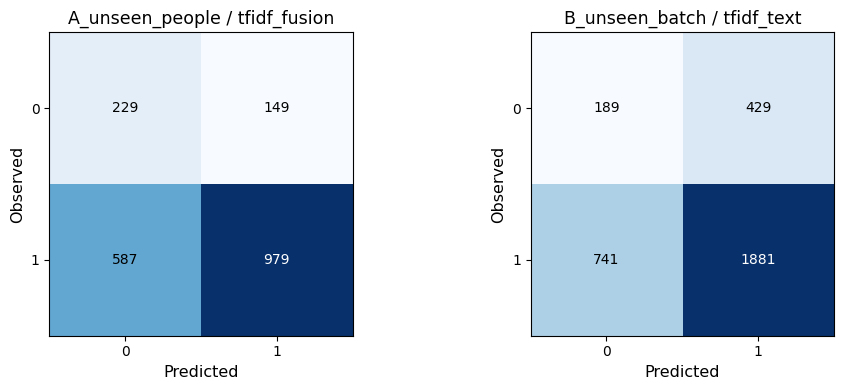

In [5]:
# ============= 04. Analyse Participant Variation and Difficulty ==============

# -------------- 1. Inspect Participant and Difficulty Summaries --------------
display(people.head())
display(strata)

# ----------------- 2. Plot Selected-Model Confusion Matrices -----------------
primary = test.merge(selected[["protocol","model"]],on=["protocol","model"])
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,row in zip(axes,primary.itertuples(index=False)):
    g=data[(data.protocol==row.protocol)&(data.model==row.model)&data.role.eq("test")]
    cm=confusion_matrix(g.is_correct,g.p_correct>=.5,labels=[0,1])
    im = ax.imshow(cm,cmap="Blues")
    for i in range(2):
        for j in range(2):
            r, g, b, _ = im.cmap(im.norm(cm[i,j]))
            luminance = 0.2126*r + 0.7152*g + 0.0722*b
            ax.text(j,i,str(cm[i,j]),ha="center",va="center",
                    color="white" if luminance < 0.5 else "black")
    ax.set(xticks=[0,1],yticks=[0,1],xlabel="Predicted",ylabel="Observed",
           title=row.protocol+" / "+row.model)
fig.tight_layout()
save_figure(fig,out_dir/"05_selected_confusion.png")
plt.show()


**05. Quantify Paired Participant Uncertainty**

Resample participant-level confusion counts jointly across candidates (1,000 draws, seed 17). The 95% percentile intervals describe pooled Test Macro F1 and matched modality differences, conditional on the fitted models and held-out participants.

The selected-model intervals are 0.5276–0.5805 in A and 0.4863–0.5211 in B. For TF-IDF fusion minus TF-IDF text, the paired differences are +0.0108 (−0.0127 to +0.0313) in A and +0.0261 (+0.0068 to +0.0432) in B. Logistic Regression and XGBoost fusion also have wholly positive intervals relative to text in B, while Random Forest fusion has wholly negative intervals relative to text in both protocols.

The 14 paired contrasts cover scalar and lexical model families, not neural modality contrasts. They are secondary, conditional and not multiplicity-adjusted. The intervals do not represent article clustering, training variability or external generalisation.

In [6]:
# ================ 05. Quantify Paired Participant Uncertainty ================

# ----------------- 1. Estimate Paired Participant Intervals ------------------
intervals, paired = participant_bootstrap(data,draws=1000,seed=17)
display(intervals)
display(paired)


,protocol,model,n_people,macro_f1_low,macro_f1_high
0,A_unseen_people,cnn_fusion,36,0.481215,0.523893
1,A_unseen_people,cnn_gaze,36,0.460960,0.512833
2,A_unseen_people,forest_fusion,36,0.454292,0.514491
3,A_unseen_people,forest_gaze,36,0.446373,0.510244
4,A_unseen_people,forest_text,36,0.522780,0.573735
5,A_unseen_people,gru_fusion,36,0.478918,0.517882
6,A_unseen_people,gru_gaze,36,0.456481,0.503592
7,A_unseen_people,logistic_fusion,36,0.439401,0.512305
8,A_unseen_people,logistic_gaze,36,0.393178,0.494620
9,A_unseen_people,logistic_text,36,0.461241,0.503007


,protocol,model_a,model_b,difference,difference_low,difference_high
0,A_unseen_people,logistic_fusion,logistic_text,-0.003547,-0.039340,0.029389
1,A_unseen_people,logistic_fusion,logistic_gaze,0.029908,0.005345,0.058481
2,A_unseen_people,forest_fusion,forest_text,-0.065794,-0.107687,-0.025081
3,A_unseen_people,forest_fusion,forest_gaze,0.007190,-0.005895,0.022808
4,A_unseen_people,xgb_fusion,xgb_text,-0.004893,-0.035034,0.023475
5,A_unseen_people,xgb_fusion,xgb_gaze,0.042159,0.024076,0.061342
6,A_unseen_people,tfidf_fusion,tfidf_text,0.003626,-0.020174,0.024455
7,B_unseen_batch,logistic_fusion,logistic_text,0.021266,0.005188,0.036365
8,B_unseen_batch,logistic_fusion,logistic_gaze,0.013245,-0.009159,0.039113
9,B_unseen_batch,forest_fusion,forest_text,-0.059949,-0.083297,-0.037544


**06. Assess Score Calibration**

Compare mean predicted score and observed correct-response fraction in ten fixed bins. Marker area reflects the number of trials in each occupied bin; the diagonal represents agreement between predicted score and observed fraction.

The selected-model Brier scores are 0.2272 in A and 0.2220 in B, compared with prevalence-reference scores of 0.1567 and 0.1544. Observed correctness exceeds mean score in eight of nine occupied A bins and all five occupied B bins. Class-weighted scores should therefore not be interpreted as calibrated probabilities. No probability recalibration or Test-driven threshold optimisation is performed.

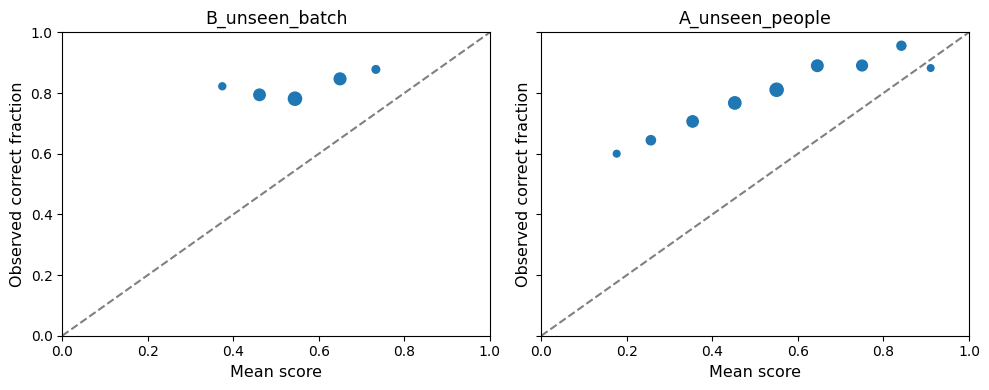

In [7]:
# ======================= 06. Assess Score Calibration ========================

# ------------------------- 1. Plot Score Calibration -------------------------
fig, axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,row in zip(axes,selected.itertuples(index=False)):
    g=calibration[(calibration.protocol==row.protocol)&(calibration.model==row.model)]
    ax.plot([0,1],[0,1],linestyle="--",color="grey")
    ax.scatter(g.mean_probability,g.observed_fraction,s=20+g.n_trials/g.n_trials.max()*70)
    ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean score",ylabel="Observed correct fraction",
           title=row.protocol)
fig.tight_layout()
save_figure(fig,out_dir/"05_score_calibration.png")
plt.show()


**07. Save Comparative Evidence and Interpret Scope**

Save the eight comparative tables and three figures in `output/`, including Validation selection, Test performance, participant and difficulty metrics, calibration bins and conditional bootstrap intervals.

**Scientific interpretation:** Paragraph-phase gaze provides model-dependent incremental information for predicting the correctness of a subsequent reading-comprehension response. It does not consistently improve on text-only predictors. Ordered neural encoders do not demonstrate a systematic advantage over the classical or lexical candidates; these comparisons do not isolate the contribution of temporal ordering. Generalisation to held-out participants and articles remains limited.

The findings concern ordinary-reading trials within OneStop. They do not establish causal gaze effects, general cognitive ability, clinical validity or external generalisation. Evaluation uses fixed saved predictions; it does not estimate variability across independent model-training runs.

In [8]:
# ============= 07. Save Comparative Evidence and Interpret Scope =============

# --------------------- 1. Save Final Comparative Tables ----------------------
for name,frame in {"05_validation_metrics.csv":validation,"05_selected_models.csv":selected,
                   "05_test_metrics.csv":test,"05_participant_metrics.csv":people,
                   "05_difficulty_metrics.csv":strata,"05_calibration_bins.csv":calibration,
                   "05_participant_intervals.csv":intervals,"05_paired_modality_intervals.csv":paired}.items():
    frame.to_csv(out_dir/name,index=False)

# ------------------------ 2. Package Current Outputs -------------------------
download_outputs_from_colab(out_dir,"05")


------------------------------------------------------------------------
Notebook 05
Files packaged: 11
  + 05_calibration_bins.csv
  + 05_difficulty_metrics.csv
  + 05_paired_modality_intervals.csv
  + 05_participant_intervals.csv
  + 05_participant_metrics.csv
  + 05_score_calibration.png
  + 05_selected_confusion.png
  + 05_selected_models.csv
  + 05_test_comparison.png
  + 05_test_metrics.csv
  + 05_validation_metrics.csv
Download ZIP from Colab Contents: /content/reading_comprehension_modelling_Notebook_05_Outputs.zip
